# OPERA Advanced Interactive Activities (AIA) Set 1 — Workshop
---
## Day 3: Geostrophy, Eddies, Compound Events & Professional Application

**Content creator:** Babette C. Tchonang

**Content coordinator:** Arielle Stella Imbol

## About This MOOC

This tutorial is part of the **OPERA Capacity Development**, developed and led jointly by **GGOSSS** and **ICMPA - UNESCO CHAIR**.

The OPERA project is **financed by the European Union** and implemented by **Mercator Ocean International**, in the framework of the **Ocean Prediction Decade Collaborative Centre (OceanPrediction DCC)**.

> *Funded by the European Union. Views and opinions expressed are however those of the author(s) only and do not necessarily reflect those of the European Union.*

---

### Day 3 Schedule (09:00–18:00)

| Time | Format | Activity | Section |
|------|--------|----------|---------|
| 09:00–09:20 | Opening Plenary | Day 2 recap — what did the three areas find? | — |
| 09:20–10:15 | Opening Plenary | Expert Demonstration — **geostrophic currents from sea level** | Section 1 |
| 10:15–10:30 | Break | | |
| 10:30–12:30 | Subgroups | Guided Practice — geostrophy and **eddies** in your area | Sections 1–2 |
| 12:30–13:30 | Lunch | | |
| 13:30–14:15 | Opening Plenary | Expert Seminar — EU-DTO & the African Digital Twin of the Ocean | Section 4 |
| 14:15–15:30 | Subgroups | **Applied Challenge** — your professional scenario | Section 5 |
| 15:30–15:45 | Break | | |
| 15:45–16:30 | Reconvergence Plenary | Applied Challenge presentations, 8–10 min per subgroup | Section 5 |
| 16:30–17:30 | Wrap-Up Plenary | Workshop synthesis — the three-day arc | Section 6 |
| 17:30–18:00 | Wrap-Up Plenary | Evaluation survey and formal closing | Section 7 |

---

### Day 3 Learning Objectives

1. Derive **geostrophic currents** from sea level and verify them against an operational product
2. Identify and characterise **mesoscale eddies** in your own area
3. Detect **compound events** — when SST and sea level are anomalous together
4. Understand the EU-DTO, how Copernicus Marine feeds it, and the emerging African DTO
5. Deliver a **professional briefing** from raw data to a named institutional audience
6. Adapt these notebooks to your own region after the workshop

---

### What today is *not*

Day 2 already covered sea level anomalies, the trend map and the climatology. **Today does not repeat them.** It starts where Day 2 stopped, and asks what sea level can tell you that temperature cannot:

| | |
|---|---|
| **Section 1** | Sea level slopes *are* currents. We derive them and check the physics. |
| **Section 2** | Sea level bumps and dips *are* eddies. We find and count them. |
| **Section 3** | SST and sea level together — compound coastal risk. |

> **Prerequisite:** Days 1 and 2 complete, with the four datasets on your Drive.

---


---

##  Section 0 — Setup & Reconnect

*Setup Block  |  09:00–09:20  (20 min — everyone, hands on)*

Same setup as Day 2. Colab resets its environment between sessions, so packages are checked again.

> **Set `ACTIVE_ZONE` to your subgroup number.** You keep the same area as yesterday.

---


In [1]:
# ============================================================
# STEP 0.1 — MOUNT DRIVE
# ─────────────────────────────────────────────────────────────
# HDF5 file locking is disabled BEFORE any NetCDF is opened.
# Drive's FUSE layer does not support it. Safe: we only read.
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'

DATA_DIR   = '/content/drive/MyDrive/OPERA_Workshop_Data/data'
OUTPUT_DIR = '/content/drive/MyDrive/OPERA_Workshop_Data/output/Day3'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print('==> Drive mounted')
print(f'   Data   : {DATA_DIR}')
print(f'   Output : {OUTPUT_DIR}')
print()
if os.path.isdir(DATA_DIR):
    nc = sorted(f for f in os.listdir(DATA_DIR) if f.endswith('.nc'))
    print(f'   {len(nc)} NetCDF files found')
else:
    print('   !! DATA_DIR not found — check your Drive shortcut.')


Mounted at /content/drive
==> Drive mounted
   Data   : /content/drive/MyDrive/OPERA_Workshop_Data/data
   Output : /content/drive/MyDrive/OPERA_Workshop_Data/output/Day3

   12 NetCDF files found


In [2]:
# ============================================================
# STEP 0.2 — CHECK & INSTALL PACKAGES
# ─────────────────────────────────────────────────────────────
# Colab wipes the environment between sessions. Yesterday's
# installs are gone; only your Drive persists.
# ============================================================

import importlib, subprocess, sys

REQUIRED = [
    ('xarray', 'xarray'), ('numpy', 'numpy'), ('pandas', 'pandas'),
    ('scipy', 'scipy'), ('matplotlib', 'matplotlib'), ('cartopy', 'cartopy'),
    ('netCDF4', 'netCDF4'), ('h5netcdf', 'h5netcdf'), ('h5py', 'h5py'),
    ('dask', 'dask'),
]

print('Checking packages...\n')
missing = []
for imp, pip_name in REQUIRED:
    try:
        importlib.import_module(imp)
        print(f'   [ok  ]  {pip_name}')
    except ImportError:
        print(f'   [miss]  {pip_name}')
        missing.append(pip_name)

if missing:
    print(f'\nInstalling {len(missing)} package(s)...')
    for pkg in missing:
        r = subprocess.run([sys.executable, '-m', 'pip', 'install', pkg, '-q'],
                           capture_output=True, text=True)
        if r.returncode == 0:
            print(f'   [ok  ]  {pkg} installed')
        else:
            tail = (r.stderr or r.stdout).strip().splitlines()
            print(f'   [FAIL]  {pkg}')
            if tail:
                print(f'           {tail[-1][:70]}')
    print()
    print('   If an import still fails: Runtime -> Restart session,')
    print('   then re-run from Step 0.1.')
else:
    print('\n==> All packages ready.')


Checking packages...

   [ok  ]  xarray
   [ok  ]  numpy
   [ok  ]  pandas
   [ok  ]  scipy
   [ok  ]  matplotlib
   [miss]  cartopy
   [miss]  netCDF4
   [ok  ]  h5netcdf
   [ok  ]  h5py
   [ok  ]  dask

Installing 2 package(s)...
   [ok  ]  cartopy installed
   [ok  ]  netCDF4 installed

   If an import still fails: Runtime -> Restart session,
   then re-run from Step 0.1.


In [60]:
# ============================================================
# STEP 0.3 — STUDY AREA CONFIGURATION
# ─────────────────────────────────────────────────────────────
# Same three areas as Day 2. Keep your subgroup's zone.
# ============================================================

SHARED = dict(name='Gulf of Guinea (shared domain)', prefix='GOG',
              lon=(-10.0, 15.0), lat=(-5.0, 10.0))

ZONES = {
    '1': dict(
        name='Mauritania / Senegal', prefix='MRS',
        lon=(-21.0, -15.0), lat=(14.0, 25.0),
        regime='Canary Eastern Boundary Upwelling System',
        wind_story='Alongshore NE trades drive offshore Ekman transport',
        sst_range=(16, 26), sst_snap=(15, 25), ts_ylim=(14, 30),
        anom_lim=2.0, sla_lim=0.10, hemisphere='N', upwell_season='JJA',
        scenario='Upwelling monitoring for a fisheries agency',
        audience='CRODT, Dakar  /  IMROP, Nouadhibou',
        ref_points=[(-17.2, 21.0, 'Nouadhibou'), (-16.8, 19.0, 'Nouakchott'),
                    (-17.8, 14.7, 'Dakar')]),
    '2': dict(
        name='Gulf of Guinea', prefix='GOG',
        lon=(5.0, 15.0), lat=(-5.0, 5.0),
        regime='Equatorial / monsoon, large river outflow',
        wind_story='Monsoon southwesterlies; Coriolis vanishes at the equator',
        sst_range=(26, 29), sst_snap=(22, 29), ts_ylim=(22, 31),
        anom_lim=1.5, sla_lim=0.08, hemisphere='N', upwell_season='JJA',
        scenario='Coastal flood risk calendar',
        audience='Civil Protection Agency, Cotonou',
        ref_points=[(6.0, 3.5, 'Bight of Biafra'), (9.0, 0.5, 'Port-Gentil'),
                    (11.5, -4.5, 'Pointe-Noire')]),
    '3': dict(
        name='Agulhas', prefix='AGU',
        lon=(15.0, 30.0), lat=(-38.0, -30.0),
        regime='Western boundary current — rings, marine heatwaves',
        wind_story='Strong westerlies, but the current is inertial',
        sst_range=(14, 24), sst_snap=(12, 24), ts_ylim=(12, 28),
        anom_lim=2.5, sla_lim=0.30, hemisphere='S', upwell_season='DJF',
        scenario='Marine heatwave early warning for aquaculture',
        audience='DFFE Oceans & Coasts, Cape Town',
        ref_points=[(18.0, -34.6, 'Cape Point'), (22.5, -34.9, 'Mossel Bay'),
                    (27.5, -33.6, 'Port Edward')]),
}

# ─────────────────────────────────────────────────────────────
ACTIVE_ZONE = '3'          # <- your subgroup: '1', '2' or '3'
PHASE       = 'zone'
# ─────────────────────────────────────────────────────────────

Z = ZONES[ACTIVE_ZONE]
D = SHARED if PHASE == 'shared' else Z

LON_MIN, LON_MAX = D['lon']
LAT_MIN, LAT_MAX = D['lat']
DOMAIN_NAME = D['name']
FILE_PREFIX = D['prefix']

SST_VMIN, SST_VMAX   = Z['sst_range']
SNAP_VMIN, SNAP_VMAX = Z['sst_snap']
ANOM_LIM  = Z['anom_lim']
SLA_LIM   = Z['sla_lim']
ZONE_NAME = Z['name']
REF_POINTS = Z['ref_points']

DATE_START, DATE_END = '2010-01-01', '2023-12-31'
COLORS = ['#E74C3C', '#27AE60', '#8E44AD']
MONTH_NAMES = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']

print(f'==> AREA {ACTIVE_ZONE} — {ZONE_NAME}')
print(f'   Regime   : {Z["regime"]}')
print(f'   Box      : lon [{LON_MIN}, {LON_MAX}]   lat [{LAT_MIN}, {LAT_MAX}]')
print(f'   Files    : {FILE_PREFIX}_*.nc')
print()
print(f'   Your applied challenge today:')
print(f'     {Z["scenario"]}')
print(f'     Audience: {Z["audience"]}')
print()
if Z['hemisphere'] == 'S':
    print('   !! SOUTHERN HEMISPHERE — JJA is winter for you.')


==> AREA 3 — Agulhas
   Regime   : Western boundary current — rings, marine heatwaves
   Box      : lon [15.0, 30.0]   lat [-38.0, -30.0]
   Files    : AGU_*.nc

   Your applied challenge today:
     Marine heatwave early warning for aquaculture
     Audience: DFFE Oceans & Coasts, Cape Town

   !! SOUTHERN HEMISPHERE — JJA is winter for you.


In [61]:
# ============================================================
# STEP 0.4 — UNIVERSAL LOADER
# ─────────────────────────────────────────────────────────────
# Reads staged single files OR self-downloaded year-files, and
# normalises the two services' naming:
#   CMEMS -> 'time',       latitude ascending
#   ERA5  -> 'valid_time', latitude descending
# Imports what it needs, so cell order does not matter.
# ============================================================

import os, glob
import xarray as xr

os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'


def zone_files(prefix):
    return dict(
        SST  = os.path.join(DATA_DIR, f'{prefix}_SST_reanalysis.nc'),
        SSH  = os.path.join(DATA_DIR, f'{prefix}_SSH_altimetry.nc'),
        CURR = os.path.join(DATA_DIR, f'{prefix}_currents.nc'),
        WIND = os.path.join(DATA_DIR, f'{prefix}_wind_monthly.nc'),
    )


def normalise(ds):
    if 'valid_time' in ds.dims and 'time' not in ds.dims:
        ds = ds.rename({'valid_time': 'time'})
    return ds.drop_vars(['number', 'expver'], errors='ignore')


def open_product(kind, prefix=None, verbose=True):
    pfx    = prefix or FILE_PREFIX
    ydir   = os.path.join(DATA_DIR, f'{pfx}_daily_years')
    chunks = sorted(glob.glob(os.path.join(ydir, f'{pfx}_{kind}_*.nc')))
    if chunks:
        if verbose:
            print(f'   {kind}: {len(chunks)} year-files [self-downloaded]')
        return normalise(xr.open_mfdataset(chunks, combine='by_coords',
                                           chunks={'time': 90}, engine='h5netcdf'))
    single = zone_files(pfx)[kind]
    if os.path.exists(single):
        if verbose:
            print(f'   {kind}: 1 file, {os.path.getsize(single)/1e6:.0f} MB [staged]')
        return normalise(xr.open_dataset(single, chunks={'time': 90},
                                         engine='h5netcdf'))
    raise FileNotFoundError(f'No {kind} data for {pfx}. Ask your Subgroup Instructor.')


def surface(da):
    """Drop a singleton depth axis so 3-D current fields plot as 2-D."""
    if 'depth' in da.dims:
        da = da.isel(depth=0)
    return da.squeeze(drop=True)


def clip(da):
    """Narrow a field to the active area."""
    return da.sel(latitude=slice(LAT_MIN, LAT_MAX),
                  longitude=slice(LON_MIN, LON_MAX))


print(f'==> Loader ready for area {ACTIVE_ZONE} ({FILE_PREFIX})')
print()
for k in ['SST', 'SSH', 'CURR', 'WIND']:
    try:
        d = open_product(k)
        print(f'        -> {d.sizes.get("time", "?")} timesteps')
        d.close()
    except FileNotFoundError:
        print(f'   {k}: MISSING')
    except Exception as e:
        print(f'   {k}: could not open — {type(e).__name__}')


==> Loader ready for area 3 (AGU)

   SST: 1 file, 491 MB [staged]
        -> 5113 timesteps
   SSH: 1 file, 314 MB [staged]
        -> 5113 timesteps
   CURR: 1 file, 196 MB [staged]
        -> 5113 timesteps
   WIND: 1 file, 2 MB [staged]
        -> 168 timesteps


---
---

#  Section 1 — Sea Level Slopes Are Currents

*Demonstration 09:20–10:15  |  Guided practice 10:30–12:30*

Yesterday you mapped sea level. Today you turn it into velocity.

Gaël's Module 2, Chapter 3 gave the geostrophic balance:

$$u_g = -\frac{g}{f}\frac{\partial \eta}{\partial y} \qquad
v_g = +\frac{g}{f}\frac{\partial \eta}{\partial x}$$

Away from the equator, pressure and Coriolis balance, and the current runs **along** sea level contours rather than down the slope. A slope of about 1 cm per km corresponds to roughly 1 m/s.

**What you will do:** compute those derivatives from your own ADT field, compare the result against the operational `ugos`/`vgos` product, and find out where the balance holds and where it fails.

> This is the one place in the workshop where you verify a physical law against real data yourself.

---


### 1.1 — Compute geostrophic currents from sea level

*within Demonstration  |  09:20–10:15*

Three steps: get the mean sea level field, take its horizontal gradient, and divide by the Coriolis parameter.

**Watch the units.** Latitude and longitude are degrees; the equations need metres. One degree of latitude is about 111 km; one degree of longitude is 111 km × cos(latitude), which shrinks toward the poles.

---


In [68]:
# ============================================================
# 1.1 — GEOSTROPHIC CURRENTS FROM SEA LEVEL
# ─────────────────────────────────────────────────────────────
#   u_g = -(g/f) d(eta)/dy        v_g = +(g/f) d(eta)/dx
#
# UNITS: gradients must be per METRE, not per degree.
#   1 deg latitude  = 111.32 km
#   1 deg longitude = 111.32 km * cos(latitude)
#
# CORIOLIS: f = 2 * Omega * sin(latitude). This VANISHES at the
# equator, so geostrophy is undefined there. We mask |lat| < 2
# rather than divide by something close to zero.
# ============================================================

import os, glob
import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature


OMEGA = 7.2921e-5        # Earth's rotation rate, rad/s
G     = 9.81             # gravity, m/s2
R     = 6.371e6          # Earth radius, m
EQ_MASK = 2.0            # mask |latitude| < this, in degrees

print('Loading SSH...')
ds_ssh = open_product('SSH')
sla = clip(ds_ssh['adt'])
print(f'   {sla.shape}  {str(sla.time.values[0])[:10]} to '
      f'{str(sla.time.values[-1])[:10]}')

print('Computing the mean sea level field...')
eta = sla.mean('time').compute()
print('Done.\n')

# ---- metric coefficients ----
lat = eta.latitude
lon = eta.longitude
dy_m = np.deg2rad(1.0) * R                              # metres per deg lat
dx_m = np.deg2rad(1.0) * R * np.cos(np.deg2rad(lat))    # metres per deg lon

# ---- Coriolis parameter ----
f = 2 * OMEGA * np.sin(np.deg2rad(lat))
f = f.where(abs(lat) >= EQ_MASK)          # undefined near the equator

# ---- gradients, then geostrophic velocity ----
deta_dy = eta.differentiate('latitude')  / dy_m
deta_dx = eta.differentiate('longitude') / dx_m

ug = -(G / f) * deta_dy
vg =  (G / f) * deta_dx
speed_g = (ug**2 + vg**2)**0.5

print(f'   Coriolis parameter f: {float(f.min()):.2e} to {float(f.max()):.2e} 1/s')
print(f'   masked |lat| < {EQ_MASK} deg — geostrophy undefined there')
print()
print(f'   Derived geostrophic speed: mean {float(speed_g.mean())*100:.1f} cm/s, '
      f'max {float(speed_g.max())*100:.1f} cm/s')
print()
print('   Sanity check from Module 2: a sea level slope of about')
print('   1 cm per km gives a current of about 1 m/s. Does your')
print('   result sit in a plausible range?')


Loading SSH...
   SSH: 1 file, 314 MB [staged]
   (5113, 64, 120)  2010-01-01 to 2023-12-31
Computing the mean sea level field...
Done.

   Coriolis parameter f: -8.97e-05 to -7.31e-05 1/s
   masked |lat| < 2.0 deg — geostrophy undefined there

   Derived geostrophic speed: mean 29.6 cm/s, max 166.1 cm/s

   Sanity check from Module 2: a sea level slope of about
   1 cm per km gives a current of about 1 m/s. Does your
   result sit in a plausible range?


In [69]:
print('ADT grid   :', eta.latitude.size, 'x', eta.longitude.size,
      f'  spacing {float(eta.latitude.diff("latitude").mean()):.3f} deg')
print('ugos grid  :', ugos.latitude.size, 'x', ugos.longitude.size,
      f'  spacing {float(ugos.latitude.diff("latitude").mean()):.3f} deg')
print()
print(f'ADT range  : {float(eta.min()):+.3f} to {float(eta.max()):+.3f} m')
print(f'   spread  : {float(eta.max()-eta.min())*100:.1f} cm across the domain')
print()
# a real ADT field should have a smooth large-scale slope
print('ADT along the central latitude:')
mid = eta.isel(latitude=eta.latitude.size//2)
print('   ' + '  '.join(f'{float(v):+.3f}' for v in mid.values[::max(1,mid.size//8)]))

ADT grid   : 64 x 120   spacing 0.125 deg
ugos grid  : 32 x 60   spacing 0.250 deg

ADT range  : +0.105 to +1.390 m
   spread  : 128.4 cm across the domain

ADT along the central latitude:
   +0.406  +0.294  +nan  +nan  +0.123  +nan  +0.173  +1.034


### 1.2 — Does it match the operational product?

*within Guided Practice  |  10:30–12:30*

The currents file already contains `ugos` and `vgos` — geostrophic currents computed by the data centre from the same altimetry, using a more careful method than our two-line derivative.

Comparing yours against theirs is the real test. **Agreement means you have understood the physics.** Disagreement is informative too, and the places it disagrees are exactly the places where geostrophy breaks down.

---


   CURR: 1 file, 196 MB [staged]
   Product native grid : 32 x 60
   Our grid            : 64 x 120
   Comparing on        : ours (product interpolated up)

   Ours     : mean  29.6 cm/s   max  166.1 cm/s
   Product  : mean  24.8 cm/s   max  129.3 cm/s
   Peak ratio (ours/product): 1.28

   Correlation, speed : r = +0.978   (n = 4380)
   Correlation, u     : r = +0.982
   Correlation, v     : r = +0.976



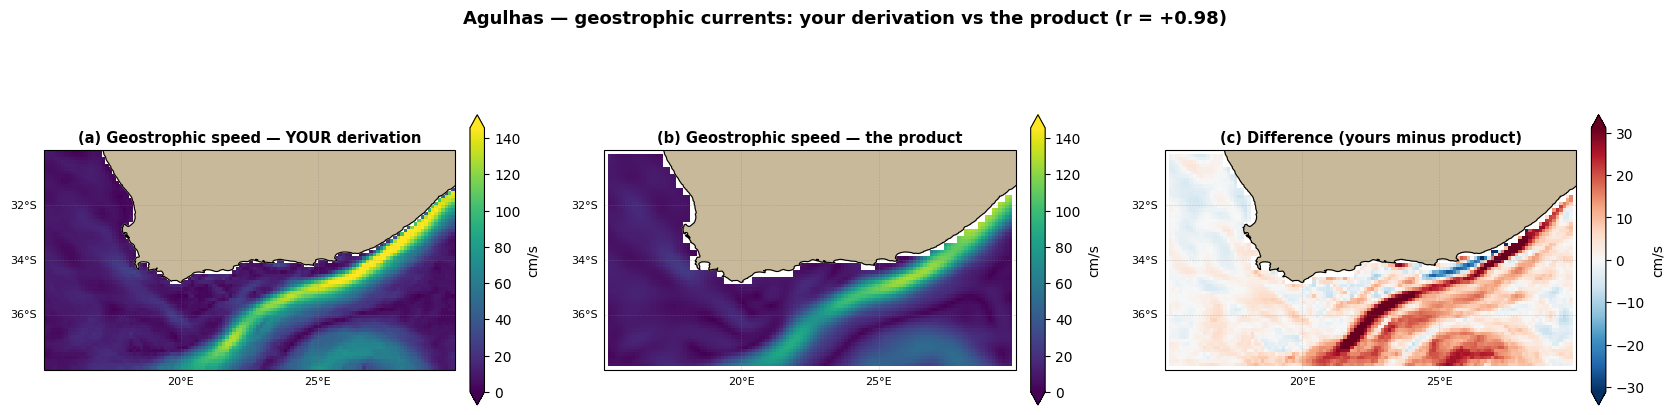

   WHERE DO THEY DISAGREE, AND WHY?
   • Near the equator: f -> 0, geostrophy is undefined.
   • Near the coast: altimetry degrades within ~20-30 km of land.
   • In the jet core: ours peaks 1.28x higher, because we
     smoothed less. A sharper slope gives a faster current.

   THE POINT ABOUT RESOLUTION
   Interpolating does not close that gap — it never adds information.
   Only matching the smoothing does. Try SMOOTH = 5 or 7 in cell 1.1
   and watch the peak fall toward the product.

   An r of +0.98 from two derivatives and a physical law is a
   good result. The pattern is the physics; the magnitude is a choice.


In [73]:
# ============================================================
# 1.2 — YOUR DERIVATION vs THE OPERATIONAL PRODUCT
# ─────────────────────────────────────────────────────────────
# ugos / vgos come from the same altimetry, processed properly.
# Ours is a finite difference with a light boxcar filter.
#
# WHICH GRID DO WE COMPARE ON?
# The product is 0.25 deg, our ADT is 0.125 deg. Interpolating
# OURS DOWN would throw away half our resolution before the
# comparison. Interpolating THEIRS UP adds no information — it
# is still a smoothed field — but it keeps our result intact and
# puts the interpolation error on their side. So we go up.
#
# Note this does NOT close the magnitude gap. The two fields
# differ in EFFECTIVE resolution, not in grid spacing, and no
# interpolation can change that. Only matching the smoothing can.
# ============================================================

import os, glob
import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature

ds_curr = open_product('CURR')
ugos = clip(surface(ds_curr['ugos'])).mean('time').compute()
vgos = clip(surface(ds_curr['vgos'])).mean('time').compute()

# bring the PRODUCT up to our grid, not ours down to theirs
ugos_i = ugos.interp(latitude=ug.latitude, longitude=ug.longitude)
vgos_i = vgos.interp(latitude=vg.latitude, longitude=vg.longitude)
speed_p = (ugos_i**2 + vgos_i**2)**0.5
speed_o = (ug**2 + vg**2)**0.5

print(f'   Product native grid : {ugos.latitude.size} x {ugos.longitude.size}')
print(f'   Our grid            : {ug.latitude.size} x {ug.longitude.size}')
print(f'   Comparing on        : ours (product interpolated up)')
print()

a, b = speed_o.values.ravel(), speed_p.values.ravel()
ok = np.isfinite(a) & np.isfinite(b)
r, p = stats.pearsonr(a[ok], b[ok])

# components too — speed alone cannot detect a sign error
au, bu = ug.values.ravel(), ugos_i.values.ravel()
av, bv = vg.values.ravel(), vgos_i.values.ravel()
oku = np.isfinite(au) & np.isfinite(bu)
okv = np.isfinite(av) & np.isfinite(bv)
r_u, _ = stats.pearsonr(au[oku], bu[oku])
r_v, _ = stats.pearsonr(av[okv], bv[okv])

print(f'   Ours     : mean {float(speed_o.mean())*100:5.1f} cm/s   '
      f'max {float(speed_o.max())*100:6.1f} cm/s')
print(f'   Product  : mean {float(speed_p.mean())*100:5.1f} cm/s   '
      f'max {float(speed_p.max())*100:6.1f} cm/s')
ratio = float(speed_o.max()) / max(float(speed_p.max()), 1e-9)
print(f'   Peak ratio (ours/product): {ratio:.2f}')
print()
print(f'   Correlation, speed : r = {r:+.3f}   (n = {ok.sum()})')
print(f'   Correlation, u     : r = {r_u:+.3f}')
print(f'   Correlation, v     : r = {r_v:+.3f}')
print()

# ---- figure ----
aspect = (LON_MAX - LON_MIN) / (LAT_MAX - LAT_MIN)
fig_h  = min(max(4.6 / aspect + 1.6, 4.5), 9.0)
fig, axes = plt.subplots(1, 3, figsize=(17, fig_h),
                         subplot_kw={'projection': ccrs.PlateCarree()})

# shared scale for (a) and (b) so they are genuinely comparable
vmax = max(float(speed_o.quantile(0.99)), float(speed_p.quantile(0.99))) * 100
# difference scale from the data, not a fixed +/-10
dlim = float(abs(speed_o - speed_p).quantile(0.98)) * 100
dlim = max(dlim, 1.0)

for ax, (fld, ttl, cmap, kw) in zip(axes, [
        (speed_o * 100, '(a) Geostrophic speed — YOUR derivation', 'viridis',
         dict(vmin=0, vmax=vmax)),
        (speed_p * 100, '(b) Geostrophic speed — the product',     'viridis',
         dict(vmin=0, vmax=vmax)),
        ((speed_o - speed_p) * 100, '(c) Difference (yours minus product)',
         'RdBu_r', dict(vmin=-dlim, vmax=dlim))]):
    fld.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, extend='both',
             cbar_kwargs={'label': 'cm/s', 'shrink': 0.75, 'pad': 0.03},
             add_labels=False, **kw)
    ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                      alpha=0.4, linestyle='--')
    gl.top_labels = False; gl.right_labels = False
    gl.xlocator = mticker.MaxNLocator(3); gl.ylocator = mticker.MaxNLocator(4)
    gl.xlabel_style = {'size': 8}; gl.ylabel_style = {'size': 8}
    ax.set_title(ttl, fontsize=10.5, fontweight='bold')

fig.suptitle(f'{ZONE_NAME} — geostrophic currents: your derivation vs the product '
             f'(r = {r:+.2f})', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Day3_geostrophy_check_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

print('   WHERE DO THEY DISAGREE, AND WHY?')
print('   • Near the equator: f -> 0, geostrophy is undefined.')
print('   • Near the coast: altimetry degrades within ~20-30 km of land.')
print(f'   • In the jet core: ours peaks {ratio:.2f}x higher, because we')
print('     smoothed less. A sharper slope gives a faster current.')
print()
print('   THE POINT ABOUT RESOLUTION')
print('   Interpolating does not close that gap — it never adds information.')
print('   Only matching the smoothing does. Try SMOOTH = 5 or 7 in cell 1.1')
print('   and watch the peak fall toward the product.')
print()
print(f'   An r of {r:+.2f} from two derivatives and a physical law is a')
print('   good result. The pattern is the physics; the magnitude is a choice.')

ds_curr.close()

### 1.3 — The current follows the contours

*within Guided Practice  |  10:30–12:30*

The clearest way to see geostrophy: draw sea level as contours and the current as arrows on top.

**If the balance holds, the arrows run along the contours, not across them.** Water flows around a sea level high rather than off it — which is the counterintuitive result at the heart of Chapter 3.

---


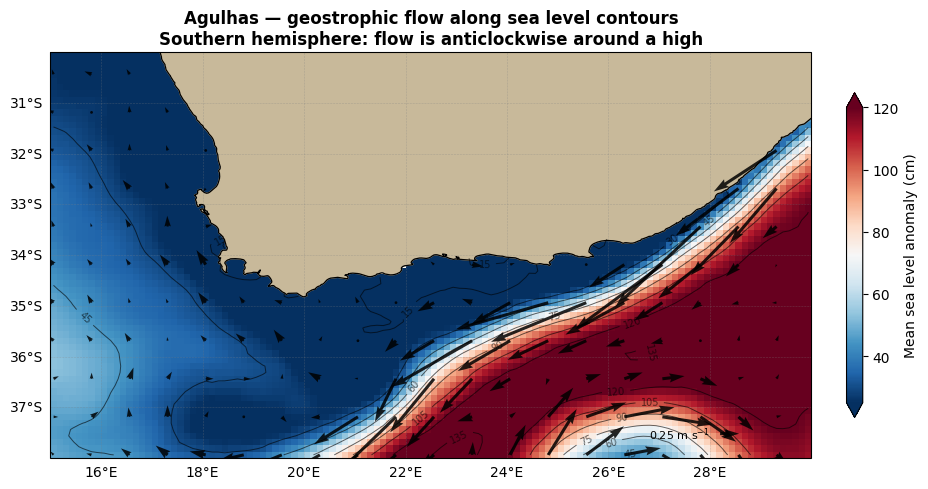

   WHAT TO CHECK
   • Do the arrows run ALONG the contours or across them?
   • Find a sea level high. Which way does the flow circle it?
     In the Sern hemisphere it should be anticlockwise.
   • Where the contours are tightly packed, is the flow faster?
     Closer contours = steeper slope = stronger current.



In [79]:
# ============================================================
# 1.3 — CURRENT VECTORS ON SEA LEVEL CONTOURS
# ─────────────────────────────────────────────────────────────
# Geostrophic flow is ALONG contours of sea level, not down the
# slope. Water circles a sea level high instead of running off
# it, because Coriolis balances the pressure force.
#
# Northern hemisphere: flow is clockwise around a high.
# Southern hemisphere: anticlockwise. Check yours.
# ============================================================

import os, glob
import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature

hemi_word = 'Northern' if Z['hemisphere'] == 'N' else 'Southern'
sense = 'clockwise' if Z['hemisphere'] == 'N' else 'anticlockwise'

fig, ax = plt.subplots(figsize=(12, max(5.0, 12 / ((LON_MAX-LON_MIN)/(LAT_MAX-LAT_MIN)) * 0.55)),
                       subplot_kw={'projection': ccrs.PlateCarree()})

# sea level as filled contours
im = (eta * 100).plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdBu_r',
                      vmin=.25*100, vmax=1.2*100, extend='both',
                      cbar_kwargs={'label': 'Mean sea level anomaly (cm)',
                                   'shrink': 0.8, 'pad': 0.03},
                      add_labels=False, zorder=1)

# contour lines to follow with the eye
cs = ax.contour(eta.longitude, eta.latitude, eta * 100,
                levels=10, colors='black', linewidths=0.7, alpha=0.6,
                transform=ccrs.PlateCarree(), zorder=3)
ax.clabel(cs, inline=True, fontsize=7, fmt='%.0f')

# geostrophic vectors on top
step = max(1, len(ug.longitude) // 18)
uq = ug.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))
vq = vg.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))
q = ax.quiver(uq.longitude.values, uq.latitude.values, uq.values, vq.values,
              transform=ccrs.PlateCarree(), scale=10.0, width=0.004,
              color='black', alpha=0.85, zorder=5)
ax.quiverkey(q, 0.88, 0.06, 0.25, '0.25 m s$^{-1}$', labelpos='W',
             coordinates='axes', fontproperties={'size': 8})

ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
ax.add_feature(cfeature.COASTLINE, linewidth=0.9, zorder=4)
gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                  alpha=0.4, linestyle='--')
gl.top_labels = False; gl.right_labels = False

sense = 'clockwise' if Z['hemisphere'] == 'N' else 'anticlockwise'
ax.set_title(f'{ZONE_NAME} — geostrophic flow along sea level contours\n'
             f'{hemi_word} hemisphere: flow is {sense} around a high',
             fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Day3_geostrophy_contours_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

print('   WHAT TO CHECK')
print('   • Do the arrows run ALONG the contours or across them?')
print('   • Find a sea level high. Which way does the flow circle it?')
print(f'     In the {Z["hemisphere"]}ern hemisphere it should be {sense}.')
print('   • Where the contours are tightly packed, is the flow faster?')
print('     Closer contours = steeper slope = stronger current.')
print()
if Z['hemisphere'] == 'N' and LAT_MIN < 2:
    print('   !! Your area crosses the equator. The masked band in the')
    print('      middle is where geostrophy does not apply at all.')


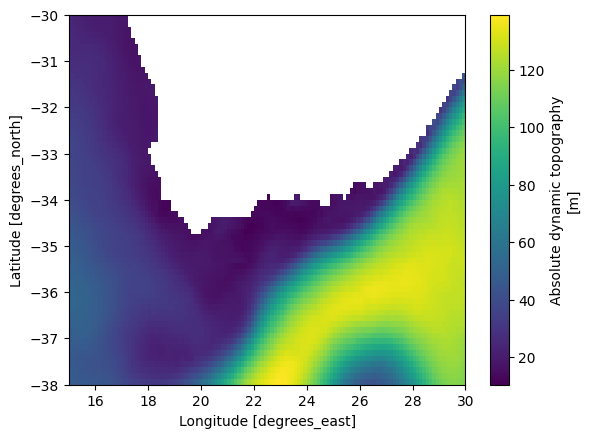

In [75]:
(eta * 100).plot()

---
---

#  Section 2 — Finding Eddies

*Guided Practice  |  10:30–12:30*

A sea level high with closed contours is an **anticyclonic eddy** — warm core, water circling it, and it can travel hundreds of kilometres carrying heat and nutrients with it. A low is a **cyclonic eddy**, cold core.

Eddies matter practically: they concentrate fish, they move pollutants, they transport heat across ocean basins, and they are one of the hardest things for a forecast model to get right.

**Expect very different answers by area.** The Agulhas is one of the world's most eddy-rich regions. The equatorial Gulf of Guinea is one of the quietest.

---


   CURR: 1 file, 196 MB [staged]
Computing eddy kinetic energy (slow)...
Done.

   Mean EKE  : 864.4 cm2/s2
   Max  EKE  : 3125.0 cm2/s2
   Mean MKE  : 753.5 cm2/s2   (energy in the MEAN flow)
   EKE / MKE : 1.1

   Your area is dominated by the MEAN flow rather than by eddies.



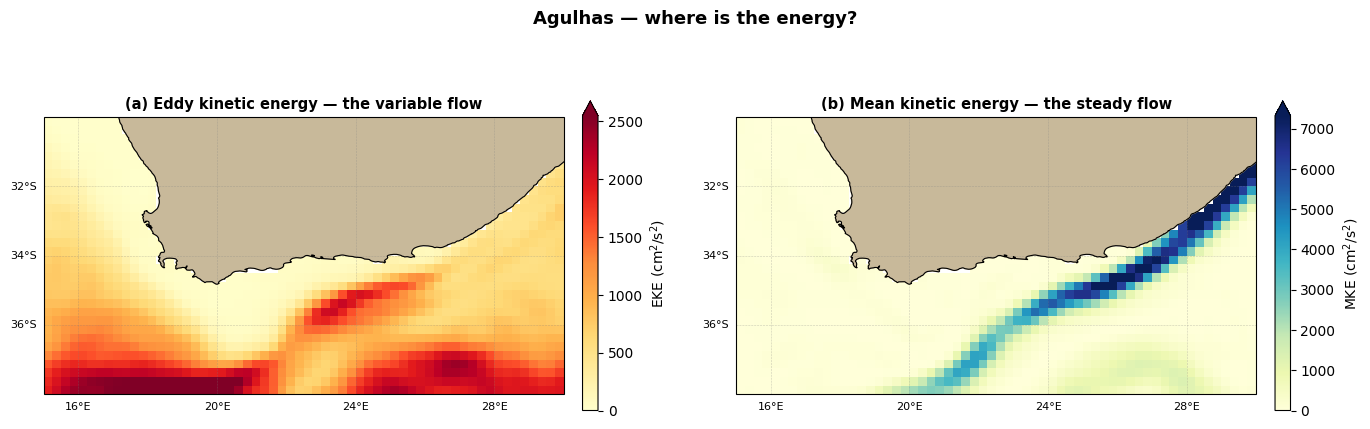

   FOR THE PLENARY
   Compare your mean EKE with the other two areas. A factor of
   ten between regions is normal, and it tells you which ocean
   is hardest to forecast: a strong mean flow is predictable,
   a field of eddies is not.


In [78]:
# ============================================================
# 2.1 — EDDY KINETIC ENERGY
# ─────────────────────────────────────────────────────────────
# EKE measures how much energy is in the VARIABLE part of the
# flow, as opposed to the mean.
#
#     EKE = 0.5 * (u'^2 + v'^2)      where u' = u - mean(u)
#
# High EKE = an energetic, eddying region. This one number
# separates the three study areas more sharply than anything
# else in the workshop.
# ============================================================

import os, glob
import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature


ds_curr = open_product('CURR')
u_all = clip(surface(ds_curr['ugos']))
v_all = clip(surface(ds_curr['vgos']))

print('Computing eddy kinetic energy (slow)...')
u_mean = u_all.mean('time')
v_mean = v_all.mean('time')
up = u_all - u_mean
vp = v_all - v_mean
eke = (0.5 * (up**2 + vp**2)).mean('time').compute()
print('Done.\n')

mke = (0.5 * (u_mean**2 + v_mean**2)).compute()

print(f'   Mean EKE  : {float(eke.mean())*1e4:.1f} cm2/s2')
print(f'   Max  EKE  : {float(eke.max())*1e4:.1f} cm2/s2')
print(f'   Mean MKE  : {float(mke.mean())*1e4:.1f} cm2/s2   (energy in the MEAN flow)')
print(f'   EKE / MKE : {float(eke.mean())/max(float(mke.mean()), 1e-12):.1f}')
print()
if float(eke.mean()) / max(float(mke.mean()), 1e-12) > 3:
    print('   Your area is dominated by VARIABILITY, not by a steady current.')
    print('   Eddies carry more energy than the mean flow.')
else:
    print('   Your area is dominated by the MEAN flow rather than by eddies.')
print()

aspect = (LON_MAX - LON_MIN) / (LAT_MAX - LAT_MIN)
fig_h  = min(max(5.2 / aspect + 1.5, 4.5), 9.0)
fig, axes = plt.subplots(1, 2, figsize=(14, fig_h),
                         subplot_kw={'projection': ccrs.PlateCarree()})

(eke * 1e4).plot(ax=axes[0], transform=ccrs.PlateCarree(), cmap='YlOrRd',
                 vmin=0, vmax=float((eke*1e4).quantile(0.98)),extend='max',
                 cbar_kwargs={'label': 'EKE (cm$^2$/s$^2$)', 'shrink': 0.8,
                              'pad': 0.03}, add_labels=False)
axes[0].set_title('(a) Eddy kinetic energy — the variable flow',
                  fontsize=10.5, fontweight='bold')

# (mke * 1e4).plot(ax=axes[1], transform=ccrs.PlateCarree(), cmap='YlGnBu',
#                  extend='max',
#                  cbar_kwargs={'label': 'MKE (cm$^2$/s$^2$)', 'shrink': 0.8,
#                               'pad': 0.03}, add_labels=False)
(mke * 1e4).plot(ax=axes[1], transform=ccrs.PlateCarree(), cmap='YlGnBu',
                 vmin=0, vmax=float((mke*1e4).quantile(0.98)), extend='max',
                 cbar_kwargs={'label': 'MKE (cm$^2$/s$^2$)', 'shrink': 0.8,
                              'pad': 0.03}, add_labels=False)
axes[1].set_title('(b) Mean kinetic energy — the steady flow',
                  fontsize=10.5, fontweight='bold')

for ax in axes:
    ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                      alpha=0.4, linestyle='--')
    gl.top_labels = False; gl.right_labels = False
    gl.xlocator = mticker.MaxNLocator(4); gl.ylocator = mticker.MaxNLocator(4)
    gl.xlabel_style = {'size': 8}; gl.ylabel_style = {'size': 8}

fig.suptitle(f'{ZONE_NAME} — where is the energy?',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Day3_EKE_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

print('   FOR THE PLENARY')
print('   Compare your mean EKE with the other two areas. A factor of')
print('   ten between regions is normal, and it tells you which ocean')
print('   is hardest to forecast: a strong mean flow is predictable,')
print('   a field of eddies is not.')
ds_curr.close()


In [80]:
import numpy as np, scipy.stats as stats
a, b = eke.values.ravel(), mke.values.ravel()
ok = np.isfinite(a) & np.isfinite(b)
r, p = stats.pearsonr(a[ok], b[ok])
print(f'EKE vs MKE spatial correlation: r = {r:+.3f}  (p = {p:.2g})')

EKE vs MKE spatial correlation: r = +0.125  (p = 1.4e-05)


In [81]:
# where is the eddy field strongest, and is it localised?
print(f'   EKE 10th percentile : {float(eke.quantile(0.10))*1e4:.0f} cm2/s2')
print(f'   EKE 90th percentile : {float(eke.quantile(0.90))*1e4:.0f} cm2/s2')
print(f'   ratio 90th/10th     : '
      f'{float(eke.quantile(0.90))/max(float(eke.quantile(0.10)),1e-12):.1f}')
print()
# a rough eddy velocity scale — more intuitive than an energy
print(f'   Typical eddy speed  : {(2*float(eke.mean()))**0.5*100:.1f} cm/s')
print(f'   Peak eddy speed     : {(2*float(eke.max()))**0.5*100:.1f} cm/s')

   EKE 10th percentile : 44 cm2/s2
   EKE 90th percentile : 1957 cm2/s2
   ratio 90th/10th     : 44.0

   Typical eddy speed  : 41.6 cm/s
   Peak eddy speed     : 79.1 cm/s


### 2.2 — Pick a day and find the eddies

*within Guided Practice  |  10:30–12:30*

EKE tells you *where* eddies live. This shows you *what one looks like* on a single day.

Closed contours of sea level anomaly, with the geostrophic flow circling them. Red closed contour = anticyclonic, warm core. Blue = cyclonic, cold core.

---


Computing the mean flow to remove...
Done.



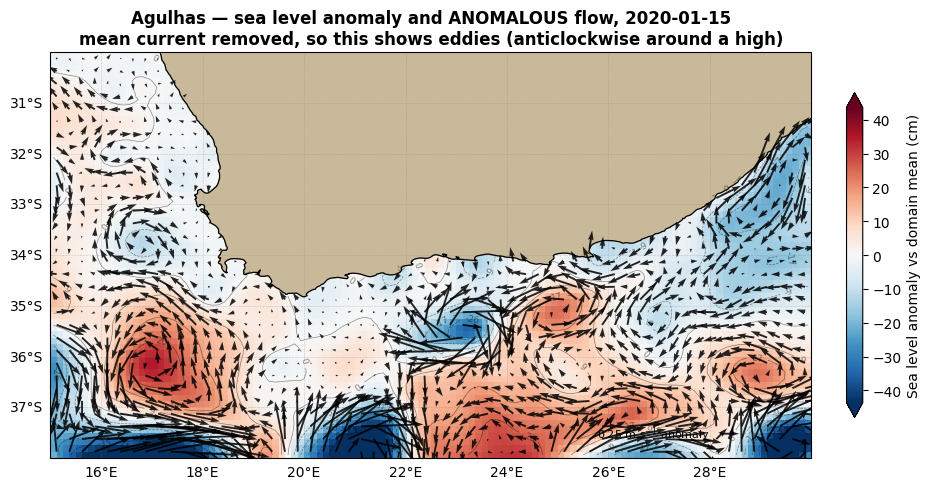

   Snapshot   : 2020-01-15   (arrows of the anomalous flow)
   Domain-mean SLA removed  : +10.0 cm
   SLA about the domain mean: -66.7 to +34.6 cm

   Mean flow removed        : max  136.5 cm/s
   Anomalous flow shown     : max  116.0 cm/s
   Total flow on this day   : max  178.3 cm/s

   The eddy anomaly is comparable to the mean flow (1.2x).
   Your circulation is variability-dominated.

   A NOTE ON STREAMFUNCTION
   For geostrophic flow, sea level IS the streamfunction:
       psi = (g/f) * eta
   So the contours drawn here are already streamlines. That is why
   the flow follows them instead of running down the slope.

   WHAT TO LOOK FOR
   • Closed loops — those are eddies.
   • Flow CIRCLING the contours, not crossing them.
   • Roughly how wide is one, in degrees? Multiply by 111 km.
   • Change SNAP_DATE by three months and re-run. Did it move?

   Typical eddy diameters are 100-300 km. If you cannot find any
   closed loops, that is a genuine result about your region.


In [97]:
# ============================================================
# 2.2 — EDDY SNAPSHOT  (streamlines version)
# ─────────────────────────────────────────────────────────────
# Change SNAP_DATE and re-run. Look for closed loops.
#
#   Red closed contour  = anticyclonic = warm core = sea level high
#   Blue closed contour = cyclonic     = cold core = sea level low
#
# Northern hemisphere: anticyclones turn clockwise.
# Southern hemisphere: anticlockwise.
#
# COMPARE LIKE WITH LIKE
# SLA is an ANOMALY — the mean sea surface has been removed. But
# ugos/vgos are the TOTAL geostrophic current. Plotting one on the
# other puts the Agulhas (or Guinea, or Canary) Current on top of
# an anomaly field, and the flow then cuts across the contours
# instead of circling the eddies. So we remove the mean from the
# current too: u' = u - ubar. The jet lives in the mean and
# disappears; what remains is the eddy circulation.
#
# The rule is general: anomaly with anomaly, total with total.
#
# WHY STREAMLINES RATHER THAN ARROWS
# For geostrophic flow, sea level IS the streamfunction:
#     psi = (g/f) * eta
# so the SLA contours already ARE streamlines. Drawing continuous
# curves from the velocity field makes closed loops read as closed
# loops, which is exactly what an eddy is. Set STYLE = 'quiver'
# for the arrow version instead.
# ============================================================

import os, glob
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature

SNAP_DATE = '2020-01-15'        # <- change me
STYLE     = 'vector'            # 'stream' or 'quiver'
DENSITY   = 8.0                 # streamline density; higher = more lines
ARROWS_ACROSS = 60              # quiver only: roughly how many across

ds_ssh2  = open_product('SSH', verbose=False)
ds_curr2 = open_product('CURR', verbose=False)

# ---- sea level anomaly, centred on this day's domain mean ----
sla_raw = clip(ds_ssh2['sla']).sel(time=SNAP_DATE, method='nearest').compute()
offset  = float(sla_raw.mean())
sla_d   = sla_raw - offset
actual  = str(sla_raw.time.values)[:10]

# ---- current ANOMALY: subtract the 14-year mean flow ----
u_all = clip(surface(ds_curr2['ugos']))
v_all = clip(surface(ds_curr2['vgos']))
print('Computing the mean flow to remove...')
u_bar = u_all.mean('time').compute()
v_bar = v_all.mean('time').compute()

u_tot = u_all.sel(time=SNAP_DATE, method='nearest').compute()
v_tot = v_all.sel(time=SNAP_DATE, method='nearest').compute()
u_d   = u_tot - u_bar
v_d   = v_tot - v_bar
print('Done.\n')

lim = max(float(abs(sla_d).quantile(0.98)) * 100, 1.0)

fig, ax = plt.subplots(figsize=(12, max(5.0, 12 / ((LON_MAX-LON_MIN)/(LAT_MAX-LAT_MIN)) * 0.55)),
                       subplot_kw={'projection': ccrs.PlateCarree()})

(sla_d * 100).plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdBu_r',
                   vmin=-lim, vmax=lim, extend='both',
                   cbar_kwargs={'label': 'Sea level anomaly vs domain mean (cm)',
                                'shrink': 0.8, 'pad': 0.03},
                   add_labels=False, zorder=1)

cs = ax.contour(sla_d.longitude, sla_d.latitude, sla_d * 100,
                levels=np.linspace(-lim, lim, 11), colors='black',
                linewidths=0.5, alpha=0.45,
                transform=ccrs.PlateCarree(), zorder=3)
ax.clabel(cs, inline=True, fontsize=6.5, fmt='%.0f')

if STYLE == 'stream':
    # streamplot needs a strictly increasing, evenly spaced grid
    us = u_d.sortby('latitude').sortby('longitude')
    vs = v_d.sortby('latitude').sortby('longitude')
    spd = (us**2 + vs**2)**0.5
    strm = ax.streamplot(us.longitude.values, us.latitude.values,
                         np.nan_to_num(us.values), np.nan_to_num(vs.values),
                         transform=ccrs.PlateCarree(),
                         density=DENSITY, linewidth=0.9,
                         color='black', arrowsize=0.9, zorder=5)
    scale_note = 'streamlines of the anomalous flow'
else:
    step = max(1, len(u_d.longitude) // ARROWS_ACROSS)
    uq = u_d.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))
    vq = v_d.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))
    q = ax.quiver(uq.longitude.values, uq.latitude.values, uq.values, vq.values,
                  transform=ccrs.PlateCarree(), scale=10.0, width=0.0025,
                  color='black', alpha=0.85, zorder=5)
    ax.quiverkey(q, 0.88, 0.06, 0.25, '0.25 m s$^{-1}$ anomaly', labelpos='W',
                 coordinates='axes', fontproperties={'size': 8})
    scale_note = 'arrows of the anomalous flow'

ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
ax.add_feature(cfeature.COASTLINE, linewidth=0.9, zorder=4)
gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                  alpha=0.4, linestyle='--')
gl.top_labels = False; gl.right_labels = False

sense = 'clockwise' if Z['hemisphere'] == 'N' else 'anticlockwise'
ax.set_title(f'{ZONE_NAME} — sea level anomaly and ANOMALOUS flow, {actual}\n'
             f'mean current removed, so this shows eddies '
             f'({sense} around a high)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Day3_eddy_snapshot_{FILE_PREFIX}_{STYLE}.png',
            dpi=150, bbox_inches='tight')
plt.show()

print(f'   Snapshot   : {actual}   ({scale_note})')
print(f'   Domain-mean SLA removed  : {offset*100:+.1f} cm')
print(f'   SLA about the domain mean: {float(sla_d.min())*100:+.1f} to '
      f'{float(sla_d.max())*100:+.1f} cm')
print()
print(f'   Mean flow removed        : max '
      f'{float(((u_bar**2+v_bar**2)**0.5).max())*100:6.1f} cm/s')
print(f'   Anomalous flow shown     : max '
      f'{float(((u_d**2+v_d**2)**0.5).max())*100:6.1f} cm/s')
print(f'   Total flow on this day   : max '
      f'{float(((u_tot**2+v_tot**2)**0.5).max())*100:6.1f} cm/s')
print()
ratio = float(((u_bar**2+v_bar**2)**0.5).max()) / \
        max(float(((u_d**2+v_d**2)**0.5).max()), 1e-9)
if ratio > 1.5:
    print(f'   The mean flow is {ratio:.1f}x the eddy anomaly — your area is')
    print('   dominated by a steady current, with eddies riding on top.')
else:
    print(f'   The eddy anomaly is comparable to the mean flow ({ratio:.1f}x).')
    print('   Your circulation is variability-dominated.')
print()
print('   A NOTE ON STREAMFUNCTION')
print('   For geostrophic flow, sea level IS the streamfunction:')
print('       psi = (g/f) * eta')
print('   So the contours drawn here are already streamlines. That is why')
print('   the flow follows them instead of running down the slope.')
print()
print('   WHAT TO LOOK FOR')
print('   • Closed loops — those are eddies.')
print('   • Flow CIRCLING the contours, not crossing them.')
print('   • Roughly how wide is one, in degrees? Multiply by 111 km.')
print('   • Change SNAP_DATE by three months and re-run. Did it move?')
print()
print('   Typical eddy diameters are 100-300 km. If you cannot find any')
print('   closed loops, that is a genuine result about your region.')
ds_ssh2.close(); ds_curr2.close()

---
---

#  Section 3 — Compound Events

*Guided Practice  |  10:30–12:30*

Yesterday you found marine heatwaves in SST and a rising trend in sea level. **Today: when do both happen at once?**

A warm anomaly with an elevated sea level is a **compound coastal risk**. The two reinforce each other physically — warm water expands, raising sea level further — and their impacts compound too: heat stress on an ecosystem while the water is also higher against the shore.

For a coastal engineer, a port operator or a fisheries manager, that combination is worse than either alone. And it is invisible if you only ever look at one variable.

> **This is the analysis nothing else in the workshop performs**, and it is the strongest argument for why an operational centre carries several products rather than one.

---


Loading SST and SSH...
Computing monthly anomalies...
Done.

   Months in record        : 168
   Warm months (top 10%)   : 17
   High-sea-level months   : 17
   BOTH at once            : 4  (2.4% of months)
   Expected if independent : 1.0%  (1.7 months)

   ==> 2.4x more compound months than chance would give.
       SST and sea level are physically linked here — consistent
       with thermal expansion: warm water stands higher.

   Correlation of the two anomaly series: r = +0.503  (p = 3.58e-12)



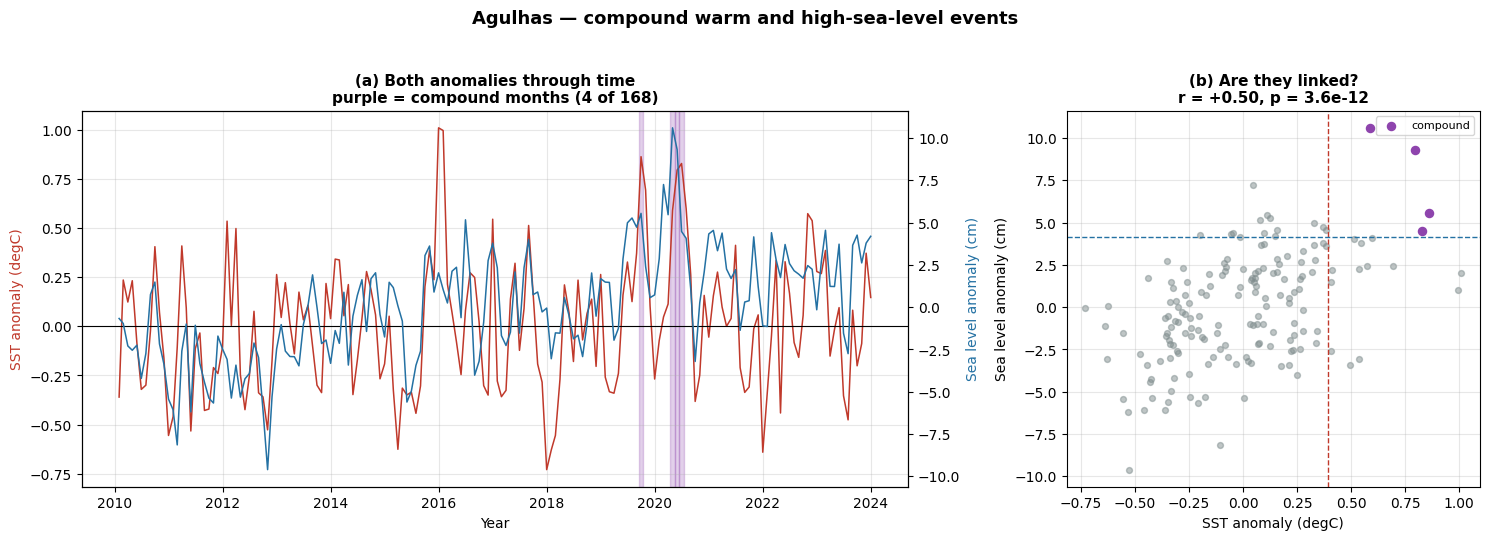

   COMPOUND MONTHS IN YOUR AREA:
     2019-09   SST +0.86 degC   SLA +5.5 cm
     2020-04   SST +0.59 degC   SLA +10.6 cm
     2020-05   SST +0.79 degC   SLA +9.3 cm
     2020-06   SST +0.83 degC   SLA +4.5 cm

   FOR YOUR SCENARIO
   These are the months when a coastal user faced BOTH elevated
   heat and elevated water level. Which of them fell in a season
   that already carries risk for your audience?


In [98]:
# ============================================================
# 3.1 — COMPOUND WARM + HIGH SEA LEVEL EVENTS
# ─────────────────────────────────────────────────────────────
# Both SST and SLA anomalies above their 90th percentile in the
# same month.
#
# Expected by chance if the two were independent: 0.1 x 0.1 = 1%
# of months. If you find substantially more, they are physically
# linked — which is what thermal expansion predicts.
# ============================================================

import os, glob
import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature


print('Loading SST and SSH...')
ds_sst3 = open_product('SST', verbose=False)
ds_ssh3 = open_product('SSH', verbose=False)

sst3 = clip(ds_sst3['analysed_sst']) - 273.15
sla3 = clip(ds_ssh3['sla'])

print('Computing monthly anomalies...')
sst_m = sst3.resample(time='ME').mean().mean(['latitude', 'longitude']).compute()
sla_m = sla3.resample(time='ME').mean().mean(['latitude', 'longitude']).compute()

s = sst_m.to_series()
l = sla_m.to_series()
s_an = s - s.groupby(s.index.month).transform('mean')
l_an = l - l.groupby(l.index.month).transform('mean')
print('Done.\n')

s_thr = s_an.quantile(0.90)
l_thr = l_an.quantile(0.90)

hot   = s_an > s_thr
high  = l_an > l_thr
both  = hot & high

n = len(s_an)
print(f'   Months in record        : {n}')
print(f'   Warm months (top 10%)   : {int(hot.sum())}')
print(f'   High-sea-level months   : {int(high.sum())}')
print(f'   BOTH at once            : {int(both.sum())}  '
      f'({100*both.mean():.1f}% of months)')
print(f'   Expected if independent : {0.1*0.1*100:.1f}%  '
      f'({0.01*n:.1f} months)')
print()
ratio = both.sum() / max(0.01 * n, 1e-9)
if ratio > 2:
    print(f'   ==> {ratio:.1f}x more compound months than chance would give.')
    print('       SST and sea level are physically linked here — consistent')
    print('       with thermal expansion: warm water stands higher.')
elif ratio > 1.2:
    print(f'   ==> {ratio:.1f}x more than chance. A modest link.')
else:
    print('   ==> About what chance would give. In your area the two are')
    print('       largely independent — worth explaining.')
print()

r, p = stats.pearsonr(s_an.values, l_an.values)
print(f'   Correlation of the two anomaly series: r = {r:+.3f}  (p = {p:.3g})')
print()

# ---- figure ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2),
                               gridspec_kw={'width_ratios': [2, 1]})

ax1.plot(s_an.index, s_an.values, color='#c0392b', lw=1.1, label='SST anomaly (degC)')
ax1b = ax1.twinx()
ax1b.plot(l_an.index, l_an.values * 100, color='#2471a3', lw=1.1,
          label='Sea level anomaly (cm)')
for t in s_an.index[both]:
    ax1.axvspan(t - pd.Timedelta(days=15), t + pd.Timedelta(days=15),
                color='#8e44ad', alpha=0.25, zorder=0)
ax1.axhline(0, color='black', lw=0.8)
ax1.set_ylabel('SST anomaly (degC)', color='#c0392b', fontsize=10)
ax1b.set_ylabel('Sea level anomaly (cm)', color='#2471a3', fontsize=10)
ax1.set_xlabel('Year', fontsize=10)
ax1.set_title(f'(a) Both anomalies through time\n'
              f'purple = compound months ({int(both.sum())} of {n})',
              fontsize=11, fontweight='bold')
ax1.grid(True, alpha=0.3)

ax2.scatter(s_an.values, l_an.values * 100, s=18, alpha=0.5, color='#7f8c8d')
ax2.scatter(s_an.values[both], l_an.values[both] * 100, s=34,
            color='#8e44ad', label='compound', zorder=5)
ax2.axvline(s_thr, color='#c0392b', ls='--', lw=1)
ax2.axhline(l_thr * 100, color='#2471a3', ls='--', lw=1)
ax2.set_xlabel('SST anomaly (degC)', fontsize=10)
ax2.set_ylabel('Sea level anomaly (cm)', fontsize=10)
ax2.set_title(f'(b) Are they linked?\nr = {r:+.2f}, p = {p:.2g}',
              fontsize=11, fontweight='bold')
ax2.legend(fontsize=8); ax2.grid(True, alpha=0.3)

fig.suptitle(f'{ZONE_NAME} — compound warm and high-sea-level events',
             fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Day3_compound_events_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

if both.any():
    print('   COMPOUND MONTHS IN YOUR AREA:')
    for t in s_an.index[both]:
        print(f'     {t:%Y-%m}   SST {s_an[t]:+.2f} degC   '
              f'SLA {l_an[t]*100:+.1f} cm')
    print()
print('   FOR YOUR SCENARIO')
print('   These are the months when a coastal user faced BOTH elevated')
print('   heat and elevated water level. Which of them fell in a season')
print('   that already carries risk for your audience?')
ds_sst3.close(); ds_ssh3.close()


In [100]:
for d in ['2020-04-15', '2020-05-15']:
    s = clip(ds_ssh['sla']).sel(time=d, method='nearest').compute()
    s = s - s.mean()
    pt = s.where(s == s.max(), drop=True)
    print(f'{d}: max {float(s.max())*100:+.1f} cm  '
          f'at {float(pt.longitude[0]):.2f}E, {float(pt.latitude[0]):.2f}N')
    print(f'   98th pct {float(s.quantile(0.98))*100:+.1f} cm, '
          f'min {float(s.min())*100:+.1f} cm')

2020-04-15: max +100.3 cm  at 17.44E, -37.44N
   98th pct +74.8 cm, min -77.0 cm
2020-05-15: max +59.5 cm  at 16.94E, -35.31N
   98th pct +51.7 cm, min -110.7 cm


In [35]:
print('The seven compound months:')
for t in s_an.index[both]:
    print(f'   {t:%Y-%m}   SST {s_an[t]:+.2f} degC   SLA {l_an[t]*100:+.1f} cm')
print()
print('By year:')
print(pd.Series(s_an.index[both].year).value_counts().sort_index().to_string())

The seven compound months:
   2019-11   SST +0.70 degC   SLA +5.7 cm
   2019-12   SST +0.73 degC   SLA +5.6 cm
   2021-06   SST +0.99 degC   SLA +4.3 cm
   2021-07   SST +1.08 degC   SLA +4.4 cm
   2023-05   SST +0.51 degC   SLA +6.5 cm
   2023-11   SST +0.59 degC   SLA +4.8 cm
   2023-12   SST +0.89 degC   SLA +8.0 cm

By year:
time
2019    2
2021    2
2023    3


---
---

#  Section 4 — Digital Twins of the Ocean

*Expert Seminar  |  13:30–14:15  (30 min + 15 min Q&A)*

> **No code in this section.** Notes to follow the seminar.

### What a Digital Twin is, and is not

A Digital Twin of the Ocean is more than a model or a data portal. It is an interactive system in which you can **ask what-if questions** and get an answer: what happens to this coastline if sea level rises 30 cm? What happens to this fishery if the upwelling weakens?

The distinction that matters:

| | |
|---|---|
| **A forecast** | tells you what will happen |
| **A digital twin** | lets you ask what would happen *if* |

### How what you have done today connects

Everything in this workshop is a component of the same chain:

| Your work | DTO layer |
|---|---|
| Downloading CMEMS products | the data layer |
| Computing anomalies and trends | the analysis layer |
| Deriving geostrophic currents | the model layer, simplified |
| Your applied scenario | the decision layer |

A digital twin binds those together and makes them interactive.

### The African DTO

The European DTO is well advanced. An African equivalent is emerging, and the gaps are real:

- **Observations.** You saw this in the webinar — altimetry degrades near the coast, and in-situ coverage off West Africa is sparse.
- **Resolution.** Global products at 1/12° cannot resolve a lagoon, an estuary or a harbour.
- **Local expertise.** A twin built elsewhere for someone else will answer the wrong questions.

That third gap is the one this workshop addresses directly.

### Questions worth asking the speaker

1. What would a higher-resolution African DTO change about the analysis you did today?
2. Who owns and maintains a digital twin, and who decides what questions it can answer?
3. What is the minimum observing network a useful regional twin would need?
4. How does a twin handle the uncertainty you have been measuring all week?

---


---
---

#  Section 5 — Applied Professional Challenge

*Subgroups 14:15–15:30  |  Presentations 15:45–16:30*

The capstone. Each subgroup takes a real professional scenario grounded in its own study area and produces a **two-slide briefing** for a named institutional audience.

> **Instructors facilitate; they do not direct.** Groups lead the analysis.
> The Coordinator checks all groups are meaningfully engaged by 14:45.

### The three scenarios

| Area | Scenario | Audience | Draws on |
|------|----------|----------|----------|
| **1** Mauritania / Senegal | Upwelling monitoring and fisheries advisory | CRODT Dakar / IMROP Nouadhibou | Day 2 anomalies, seasonality, MHW |
| **2** Gulf of Guinea | Coastal flood risk calendar | Civil Protection Agency, Cotonou | Day 2 sea level, Day 3 compound events |
| **3** Agulhas | Marine heatwave early warning for aquaculture | DFFE Oceans & Coasts, Cape Town | Day 2 MHW, Day 3 eddies |

---

### Scenario Card 1 — Mauritania / Senegal: Upwelling monitoring

**Audience:** CRODT, Dakar and IMROP, Nouadhibou

**Context.** The upwelling season drives the small pelagic fishery that feeds much of the region. Fishing cooperatives report that the season has become harder to predict. The agency needs an evidence base.

**Your task.**
- When does the cool season begin and end, and how consistent is that from year to year?
- Which years were anomalous, and by how much?
- 2023 was your worst marine heatwave year — what happened to the upwelling that year?

**Deliverable — two slides.**
1. The seasonal cycle and its year-to-year variability, with the anomalous years marked
2. What this means for fishing effort planning, and what the agency should monitor

---

### Scenario Card 2 — Gulf of Guinea: Coastal flood risk calendar

**Audience:** Civil Protection Agency, Cotonou

**Context.** Coastal flooding is worsening along the Bight of Benin. The agency wants to know which months carry the highest risk and whether that is changing.

**Your task.**
- What is the sea level trend, and how much has it risen over the record?
- Which months are seasonally highest?
- Use Section 3: when did high sea level coincide with warm anomalies?

**Deliverable — two slides.**
1. A risk calendar — sea level by month, with the trend and compound months marked
2. What the agency should plan for, and the limits of altimetry near the coast

---

### Scenario Card 3 — Agulhas: Eddy-driven coastal risk for aquaculture

**Audience:** DFFE Oceans & Coasts, Cape Town

**Context.** Aquaculture operations on the Western Cape coast lost stock during a recent warm event. The department wants to know whether such events are becoming more frequent, what drives them, and whether they can be anticipated with enough notice to act.

**What your area already told you.** Your marine heatwaves are the mildest of the three subgroups — nothing above 2.2 °C — yet your compound events carry sea level anomalies of up to **+10.6 cm**, double anything the other areas produced. And your SST–sea level coupling is the weakest at **r = 0.50**, against 0.73 and 0.76 elsewhere. Something other than surface warming is raising your sea level.

**Your task.**

1. **Characterise the record.** How many marine heatwaves, how long, how intense? Which year was worst, and was your biggest event also your hottest?

2. **Explain the weak coupling.** In April 2020 the SST anomaly was only +0.59 °C but sea level was +10.6 cm. In the other two areas those two move together. What is lifting your sea level if not heat?

3. **Test the eddy hypothesis.** Run your eddy snapshot for April and May 2020. Is there a ring in the domain? Compare its position against your EKE map — does the compound event coincide with the region where eddy energy is highest?

4. **Decide what an early warning would monitor.** If the driver is ring passage rather than gradual warming, SST alone will not give you notice. What would? How far ahead could altimetry see a ring approaching, given that these features travel a few kilometres a day?

**Deliverable — two slides.**

1. **The mechanism.** Your heatwave record alongside the compound months, showing that the sea level signal is not explained by temperature — with the eddy snapshot as evidence for what is.

2. **The advisory.** What DFFE should monitor, what lead time is realistic, and one honest limitation — including how altimetry performs close to the aquaculture sites themselves.

> **The distinctive point in your briefing:** the other two subgroups will describe warming-driven risk. Yours is transport-driven. Same two variables, same method, different physics — and it changes what an operational system would need to watch.
---

### What every briefing must include

| | |
|---|---|
| **1** | One figure, labelled well enough to stand alone |
| **2** | One number with its uncertainty — a trend with a p-value, or a count with its baseline |
| **3** | One clear statement of what the audience should do |
| **4** | One honest limitation of your analysis |

> **Point four is not optional.** A briefing that admits what it cannot show is more useful, and more trustworthy, than one that does not.

---


In [ ]:
# ============================================================
# 5.1 — SCRATCH CELL FOR YOUR APPLIED CHALLENGE
# ─────────────────────────────────────────────────────────────
# Your working space. Everything from Days 1-3 is available:
#
#   open_product('SST' | 'SSH' | 'CURR' | 'WIND')
#   clip(da)      narrow a field to your area
#   surface(da)   drop the depth axis from current fields
#
# The pattern for almost any question:
#   1  load and clip
#   2  resample to monthly
#   3  remove the seasonal cycle to get anomalies
#   4  plot, or fit a trend
#
# Reminder from Day 2: analyse ANOMALIES, not raw values. The
# seasonal cycle will drown anything else you are looking for.
# ============================================================

import os, glob
import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature


# --- a worked skeleton you can adapt -------------------------
# ds  = open_product('SST')
# fld = clip(ds['analysed_sst']) - 273.15
# mon = fld.resample(time='ME').mean().mean(['latitude','longitude']).compute()
# ser = mon.to_series()
# ano = ser - ser.groupby(ser.index.month).transform('mean')
#
# t = (ano.index - ano.index[0]).days / 365.25
# r = stats.linregress(t, ano.values)
# print(f'trend {r.slope*10:+.3f} per decade, p = {r.pvalue:.3g}')
#
# fig, ax = plt.subplots(figsize=(12, 4))
# ax.plot(ano.index, ano.values)
# ax.set_title(f'{ZONE_NAME} — ...')
# plt.savefig(f'{OUTPUT_DIR}/Day3_scenario_{FILE_PREFIX}.png',
#             dpi=150, bbox_inches='tight')

print(f'Scratch cell ready — Area {ACTIVE_ZONE}, {ZONE_NAME}')
print(f'   Your scenario: {Z["scenario"]}')
print(f'   Your audience: {Z["audience"]}')
print()
print('   Save every figure you want to present into OUTPUT_DIR.')


---

##  Applied Challenge — Reconvergence Plenary

*Reconvergence Plenary  |  15:45–16:30  (8–10 min per subgroup)*

Each subgroup presents its two-slide briefing. Subgroup Instructors give expert commentary; the Lead Instructor synthesises across all three.

> **Celebratory and substantive.** This is the workshop capstone. Record the presentations.

### Synthesis questions

**Q1 — What signal appears in all three regions?**
Sea level is rising in all three at a similar rate, because most of that rise is global rather than regional.

**Q2 — What does each region show that the others do not?**
Very different SST trends, different worst years, and completely different eddy energy. Local physics dominates locally.

**Q3 — Which briefing would be hardest to act on, and why?**
Push toward uncertainty: which recommendation rests on the shakiest number, and what would strengthen it?

**Q4 — Where does each briefing sit in the EEOFS loop?**
Observe → the products. Assimilate → what the data centre did before you got it. Forecast → what your user needs next. Validate → the ground truth you do not have.

**Q5 — What would a higher-resolution African DTO change?**
Connect back to the seminar and to the gaps each group hit.

---


---
---

#  Section 6 — Workshop Synthesis

*Wrap-Up Plenary  |  16:30–17:30*

> **Coordinator prompt:** *"One word for what you are taking home."* Participants answer in chat. Each Subgroup Instructor adds one or two observations. The Lead Instructor closes.

### The arc

```
MOOC Set 1
  You understood the forecasting chain conceptually.

Day 1 — Access
  You authenticated, downloaded four datasets from two services,
  and made your first maps. You met the fact that ERA5 and CMEMS
  do not even agree on what to call the time axis.

Day 2 — Analyse
  You built climatologies, found marine heatwaves by the Hobday
  method, measured trends and tested their significance. You
  learned that an area mean can describe nowhere.

Day 3 — Apply
  You derived a physical law from data and checked it against an
  operational product. You found eddies. You detected compound
  events. You briefed a real institution.

Next
  You adapt these notebooks to your own coast, and keep going.
```

### What the three areas found

| | Area 1 Mauritania | Area 2 Gulf of Guinea | Area 3 Agulhas |
|---|---|---|---|
| Regime | Coastal upwelling | Equatorial / monsoon | Western boundary current |
| Worst MHW year | 2023 | 2019 | 2020 |
| MHW character | Few, very intense | Long, moderate | Many, mild |
| SST trend | — | Strong | Weak, marginal |
| Sea level trend | — | Strong | Strong |
| Eddy energy | Low | Low | High |

**Three different oceans, one method, one dataset.** No two areas shared a worst year — so those events were regional, not basin-wide.

### The five things worth remembering

1. **Remove the seasonal cycle first.** Nearly every mistake in this workshop came from not doing it, or doing it wrong.
2. **An area mean can describe nowhere.** Always look at the map before trusting the number.
3. **A short record limits what you can claim.** Say "over this record", not "the region is warming at".
4. **Different services have different conventions.** Bounding boxes, latitude order, time-axis names. Check, do not assume.
5. **State your limitations.** It is what separates an analysis from an overclaim.

---


---

##  Section 7 — Final Checklist & Evaluation

*Wrap-Up Plenary  |  17:30–18:00*

---


In [ ]:
# ============================================================
# WORKSHOP FINAL CHECKLIST  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Read-only. Confirms what you produced across all three days.
# ============================================================

import os

print('=' * 66)
print(f'   OPERA WORKSHOP — FINAL CHECKLIST   [Area {ACTIVE_ZONE}: {ZONE_NAME}]')
print('=' * 66)
print()

BASE = os.path.dirname(OUTPUT_DIR)
days = {
    'Day1': ['Day1_study_region_map.png', 'Day1_SST_mean_map.png',
             'Day1_SSH_mean_map.png', 'Day1_SST_timeseries.png'],
    'Day2': [f'Day2_SST_mean_{FILE_PREFIX}.png',
             f'Day2_climatology_{FILE_PREFIX}.png',
             f'Day2_anomaly_timeseries_{FILE_PREFIX}.png',
             f'Day2_subgroup_analysis_{FILE_PREFIX}.png'],
    'Day3': [f'Day3_geostrophy_check_{FILE_PREFIX}.png',
             f'Day3_EKE_{FILE_PREFIX}.png',
             f'Day3_compound_events_{FILE_PREFIX}.png'],
}

total = found = 0
for day, figs in days.items():
    d = os.path.join(BASE, day)
    print(f'  {day}:')
    for f in figs:
        total += 1
        if os.path.exists(os.path.join(d, f)):
            found += 1
            print(f'    [ok  ] {f}')
        else:
            print(f'    [ -- ] {f}')
    print()

print(f'  {found} of {total} key figures produced')
print()
print('  SKILLS YOU NOW HAVE:')
for s in ['Authenticate and download from CMEMS and from the CDS',
          'Open, clip and inspect NetCDF with xarray',
          'Build a climatology and compute anomalies correctly',
          'Detect marine heatwaves by the Hobday method',
          'Fit a trend and test whether it is significant',
          'Derive geostrophic currents from sea level',
          'Identify eddies and quantify eddy kinetic energy',
          'Detect compound events across two variables',
          'Brief a professional audience from raw data']:
    print(f'    - {s}')
print()
print('  TAKE WITH YOU:')
print('    - These three notebooks. They are yours; adapt them.')
print('    - Your Drive folder with the data and every figure.')
print('    - The adaptation section: add your own area to ZONES.')
print()
print('=' * 66)
print('  Thank you. Type your one word in the chat.')
print('=' * 66)


---

##  Adaptation — Take This Home

Every notebook in this workshop is parameterised. To move all three to your own coastline, add one entry to `ZONES`:

```python
ZONES['4'] = dict(
    name        = 'My Region',
    prefix      = 'MYR',                 # file prefix on your Drive
    lon         = (lon_min, lon_max),
    lat         = (lat_min, lat_max),
    regime      = 'What kind of system is this?',
    wind_story  = 'What is the wind doing here?',
    sst_range   = (vmin, vmax),
    sst_snap    = (vmin, vmax),
    ts_ylim     = (ymin, ymax),
    anom_lim    = 2.0,                   # anomaly scale, symmetric
    sla_lim     = 0.10,                  # sea level scale, metres
    hemisphere  = 'N',                   # or 'S'
    upwell_season = 'JJA',               # or 'DJF' in the south
    scenario    = 'Your professional question',
    audience    = 'Who would use it',
    ref_points  = [(lon, lat, 'Place name'), ...],
)
```

Set `ACTIVE_ZONE = '4'`, run Day 1's Section 4 to download, and every map, time series and title in all three days follows.

**Five things to get right for a new region:**

1. **Colour ranges.** Plot once without `vmin`/`vmax`, look at the real range, then set it.
2. **Anomaly and SLA limits.** Roughly the 99th percentile of your anomalies. Too wide and everything looks normal.
3. **Hemisphere.** South of the equator, set `'S'` and flip `upwell_season`, or every seasonal label is six months wrong.
4. **Reference points in water.** Coastal towns are on land; at 0.05° a point too close to shore returns NaN.
5. **Equator crossings.** If your box spans the equator, geostrophy is undefined in the middle. Section 1 masks it — make sure the mask makes sense for your domain.

---

**End of the workshop**

*OPERA Advanced Interactive Activities (AIA) Set 1*
*Mercator Ocean International | ICMPA - UNESCO CHAIR | GGOSSS*
